# Day 2 — Restaurant Segmentation
## Uber Eats Operational & Customer Intelligence System



## 1. Import libraries and set project paths

In [3]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = PROJECT_ROOT / "data" / "raw"
PROCESSED = PROJECT_ROOT / "data" / "processed"
OUTPUTS = PROJECT_ROOT / "outputs" / "restaurant_segmentation"
MODELS = PROJECT_ROOT / "models"

for folder in [PROCESSED, OUTPUTS, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Raw data folder exists:", RAW.exists())

Project root: /home/nineleaps/Downloads/uber_eats-ML
Raw data folder exists: True


## 2. Load and inspect data

In [4]:
restaurants = pd.read_csv(RAW / "restaurants.csv")
orders = pd.read_csv(RAW / "orders.csv", parse_dates=["order_timestamp"])
deliveries = pd.read_csv(RAW / "deliveries.csv")
reviews = pd.read_csv(RAW / "reviews.csv")

print("Restaurants:", restaurants.shape)
print("Orders:", orders.shape)
print("Deliveries:", deliveries.shape)
print("Reviews:", reviews.shape)

display(restaurants.head())
display(orders.head())
display(deliveries.head())

Restaurants: (45, 6)
Orders: (1800, 8)
Deliveries: (1800, 9)
Reviews: (1147, 6)


,restaurant_id,restaurant_name,category,city,restaurant_rating,avg_prep_time_minutes
0,REST001,Restaurant 001,Cafe,Mumbai,3.8,18
1,REST002,Restaurant 002,Chinese,Mumbai,4.0,14
2,REST003,Restaurant 003,Cafe,Chennai,4.1,23
3,REST004,Restaurant 004,Desserts,Bengaluru,3.7,17
4,REST005,Restaurant 005,Healthy,Mumbai,4.3,32


,order_id,customer_id,restaurant_id,order_timestamp,order_amount_inr,number_of_items,preparation_time_minutes,order_status
0,ORD00001,CUST0296,REST007,2026-02-05 11:57:00,676.47,4,16,Failed
1,ORD00002,CUST0194,REST012,2026-02-06 19:41:00,387.77,1,24,Delivered
2,ORD00003,CUST0264,REST044,2026-02-20 21:24:00,460.51,1,33,Delivered
3,ORD00004,CUST0194,REST008,2026-02-18 08:38:00,797.93,4,22,Delivered
4,ORD00005,CUST0114,REST041,2026-01-10 12:50:00,1007.59,3,15,Delivered


,delivery_id,order_id,driver_id,delivery_distance_km,delivery_time_minutes,weather,traffic_condition,tip_amount_inr,delivery_status
0,DEL00001,ORD00001,DRV022,5.55,NaN,Clear,Moderate,0.00,Not completed
1,DEL00002,ORD00002,DRV005,1.77,34.0,Cloudy,Moderate,0.00,Completed
2,DEL00003,ORD00003,DRV056,3.77,48.0,Clear,Low,23.03,Completed
3,DEL00004,ORD00004,DRV005,7.45,64.0,Cloudy,Low,63.83,Completed
4,DEL00005,ORD00005,DRV045,9.31,86.0,Rain,High,80.61,Completed


In [5]:
for name, frame in {
    "restaurants": restaurants,
    "orders": orders,
    "deliveries": deliveries,
    "reviews": reviews
}.items():
    print(f"\n{name} missing values:")
    display(frame.isna().sum())
print("\nOrder statuses:")
display(orders["order_status"].value_counts(dropna=False))
print("\nDelivery statuses:")
display(deliveries["delivery_status"].value_counts(dropna=False))


restaurants missing values:


restaurant_id            0
restaurant_name          0
category                 0
city                     0
restaurant_rating        0
avg_prep_time_minutes    0
dtype: int64


orders missing values:


order_id                    0
customer_id                 0
restaurant_id               0
order_timestamp             0
order_amount_inr            0
number_of_items             0
preparation_time_minutes    0
order_status                0
dtype: int64


deliveries missing values:


...

review_id           0
order_id            0
customer_id         0
rating              0
review_text         0
review_timestamp    0
dtype: int64


Order statuses:


order_status
Delivered    1624
Cancelled     135
Failed         41
Name: count, dtype: int64


Delivery statuses:


delivery_status
Completed        1624
Not completed     176
Name: count, dtype: int64

## 3. Feature engineering

Create one row per restaurant with the requested features:
- total orders
- revenue from delivered orders
- average rating (customer review average when available, otherwise restaurant's listed rating)
- average preparation time
- cancellation rate
- average delivery time for completed deliveries

`restaurant_id` and `restaurant_name` are retained for reporting, but not included in model training.

In [6]:
# Total order volume includes all order attempts.
order_summary = orders.groupby("restaurant_id").agg(
    total_orders=("order_id", "nunique"),
    cancelled_orders=("order_status", lambda s: s.astype(str).str.lower().isin(["cancelled", "canceled"]).sum()),
    average_prep_time=("preparation_time_minutes", "mean")
).reset_index()

# Revenue is calculated from delivered orders only.
delivered_orders = orders[orders["order_status"].astype(str).str.lower().eq("delivered")].copy()
revenue_summary = delivered_orders.groupby("restaurant_id").agg(
    revenue=("order_amount_inr", "sum")
).reset_index()

# Attach restaurant ID to delivery records via order_id.
delivery_orders = deliveries.merge(
    orders[["order_id", "restaurant_id"]], on="order_id", how="left"
)
completed_deliveries = delivery_orders[
    delivery_orders["delivery_status"].astype(str).str.lower().eq("completed")
].copy()
delivery_summary = completed_deliveries.groupby("restaurant_id").agg(
    average_delivery_time=("delivery_time_minutes", "mean")
).reset_index()

# Customer review average per restaurant, using the order-to-restaurant relationship.
restaurant_reviews = reviews.merge(
    orders[["order_id", "restaurant_id"]], on="order_id", how="left"
)
rating_summary = restaurant_reviews.groupby("restaurant_id").agg(
    customer_review_average=("rating", "mean")
).reset_index()

restaurant_features = restaurants.merge(order_summary, on="restaurant_id", how="left")
restaurant_features = restaurant_features.merge(revenue_summary, on="restaurant_id", how="left")
restaurant_features = restaurant_features.merge(delivery_summary, on="restaurant_id", how="left")
restaurant_features = restaurant_features.merge(rating_summary, on="restaurant_id", how="left")

restaurant_features["total_orders"] = restaurant_features["total_orders"].fillna(0)
restaurant_features["cancelled_orders"] = restaurant_features["cancelled_orders"].fillna(0)
restaurant_features["revenue"] = restaurant_features["revenue"].fillna(0)
restaurant_features["average_prep_time"] = restaurant_features["average_prep_time"].fillna(
    restaurant_features["avg_prep_time_minutes"]
)
restaurant_features["average_delivery_time"] = restaurant_features["average_delivery_time"].fillna(
    delivery_orders["delivery_time_minutes"].median()
)
restaurant_features["average_rating"] = restaurant_features["customer_review_average"].fillna(
    restaurant_features["restaurant_rating"]
)
restaurant_features["cancellation_rate"] = (
    restaurant_features["cancelled_orders"] / restaurant_features["total_orders"].replace(0, np.nan)
).fillna(0)

restaurant_features = restaurant_features.round({
    "revenue": 2,
    "average_rating": 2,
    "average_prep_time": 2,
    "cancellation_rate": 3,
    "average_delivery_time": 2
})

display(restaurant_features.head())
print("Restaurant feature dataset shape:", restaurant_features.shape)

,restaurant_id,restaurant_name,category,city,restaurant_rating,avg_prep_time_minutes,total_orders,cancelled_orders,average_prep_time,revenue,average_delivery_time,customer_review_average,average_rating,cancellation_rate
0,REST001,Restaurant 001,Cafe,Mumbai,3.8,18,37,4,18.0,16384.27,46.34,4.000000,4.00,0.108
1,REST002,Restaurant 002,Chinese,Mumbai,4.0,14,44,6,14.0,20311.45,49.21,3.666667,3.67,0.136
2,REST003,Restaurant 003,Cafe,Chennai,4.1,23,39,1,23.0,20143.21,53.54,3.517241,3.52,0.026
3,REST004,Restaurant 004,Desserts,Bengaluru,3.7,17,46,4,17.0,23259.45,43.62,4.071429,4.07,0.087
4,REST005,Restaurant 005,Healthy,Mumbai,4.3,32,48,1,32.0,25764.34,63.34,3.257143,3.26,0.021


Restaurant feature dataset shape: (45, 14)


## 4. Feature selection and missing-value treatment

The six requested numeric features are used for clustering. Restaurant IDs, names, city, and cuisine category are excluded from model training; they remain available for reporting and interpretation. Because the chosen model features are numeric, categorical encoding is not required. If you later add category or city to the model, use one-hot encoding before clustering.

In [7]:
FEATURES = [
    "total_orders",
    "revenue",
    "average_rating",
    "average_prep_time",
    "cancellation_rate",
    "average_delivery_time"
]

X = restaurant_features[FEATURES].copy()
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True))

print("Model features:", FEATURES)
print("Missing values after treatment:", int(X.isna().sum().sum()))
print("Identifier excluded:", "restaurant_id" not in X.columns)
display(X.describe().round(2))

Model features: ['total_orders', 'revenue', 'average_rating', 'average_prep_time', 'cancellation_rate', 'average_delivery_time']
Missing values after treatment: 0
Identifier excluded: True


,total_orders,revenue,average_rating,average_prep_time,cancellation_rate,average_delivery_time
count,45.00,45.00,45.00,45.00,45.00,45.00
mean,40.00,19391.11,3.67,22.02,0.07,52.48
std,7.02,4125.87,0.26,7.91,0.04,8.13
min,27.00,12802.22,3.14,8.00,0.00,37.85
25%,34.00,16151.85,3.48,15.00,0.04,45.68
50%,40.00,19235.45,3.65,23.00,0.07,50.92
75%,45.00,21725.33,3.89,29.00,0.09,60.20
max,56.00,29031.39,4.17,35.00,0.20,66.69


## 5. Standardization

StandardScaler places the selected features on comparable scales. This is important because revenue and order counts can be much larger numerically than ratings or cancellation rates, and distance-based algorithms could otherwise be dominated by large-scale columns.

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
joblib.dump(scaler, MODELS / "restaurant_standard_scaler.joblib")

print("Scaled matrix shape:", X_scaled.shape)
print("Approximate feature means:", np.round(X_scaled.mean(axis=0), 2))
print("Approximate feature standard deviations:", np.round(X_scaled.std(axis=0), 2))

Scaled matrix shape: (45, 6)
Approximate feature means: [ 0. -0. -0. -0. -0.  0.]
Approximate feature standard deviations: [1. 1. 1. 1. 1. 1.]


## 6. K-Means — Elbow method and Silhouette Score

Test a small range of cluster counts. The elbow plot helps identify diminishing improvement in inertia; the silhouette score provides a second comparison of cluster separation.

,k,inertia,silhouette_score
0,2,176.417,0.298
1,3,131.106,0.302
2,4,106.927,0.271
3,5,87.765,0.294
4,6,76.262,0.266
5,7,67.958,0.257
6,8,62.661,0.254


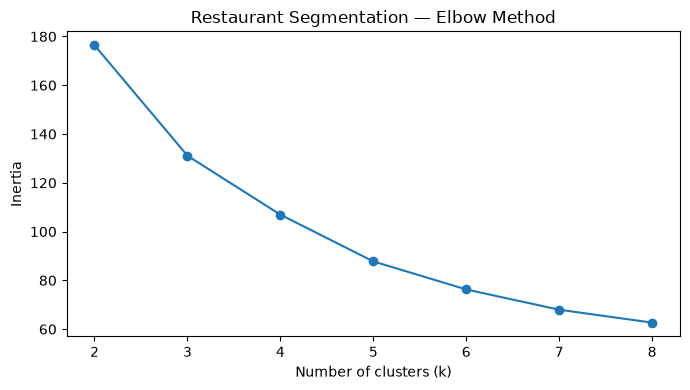

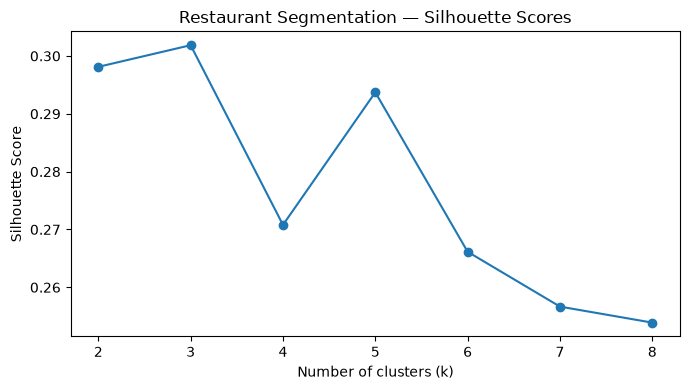

Selected k based on highest tested silhouette score: 3


In [9]:
k_values = range(2, min(9, len(restaurant_features)))
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

score_table = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette_score": silhouette_scores
})
display(score_table.round(3))

plt.figure(figsize=(7, 4))
plt.plot(score_table["k"], score_table["inertia"], marker="o")
plt.title("Restaurant Segmentation — Elbow Method")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig(OUTPUTS / "restaurant_elbow_plot.png", dpi=150)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(score_table["k"], score_table["silhouette_score"], marker="o")
plt.title("Restaurant Segmentation — Silhouette Scores")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig(OUTPUTS / "restaurant_silhouette_scores.png", dpi=150)
plt.show()

best_k = int(score_table.loc[score_table["silhouette_score"].idxmax(), "k"])
print("Selected k based on highest tested silhouette score:", best_k)

In [10]:
kmeans_restaurant = KMeans(n_clusters=best_k, random_state=42, n_init=10)
restaurant_features["kmeans_cluster"] = kmeans_restaurant.fit_predict(X_scaled)
joblib.dump(kmeans_restaurant, MODELS / "restaurant_kmeans.joblib")

print("K-Means silhouette score:",
      round(silhouette_score(X_scaled, restaurant_features["kmeans_cluster"]), 3))
display(restaurant_features["kmeans_cluster"].value_counts().sort_index().rename("restaurant_count").to_frame())

K-Means silhouette score: 0.302


,restaurant_count
kmeans_cluster,
0,11
1,21
2,13


## 7. DBSCAN — Dense groups and noise

DBSCAN finds dense groups and labels outliers as `-1`. Its output depends strongly on `eps` and `min_samples`; because there are only 45 synthetic restaurants, it is normal for a baseline setting to find few groups or label many rows as noise.

In [11]:
dbscan_restaurant = DBSCAN(eps=1.5, min_samples=3)
dbscan_labels = dbscan_restaurant.fit_predict(X_scaled)
restaurant_features["dbscan_cluster"] = dbscan_labels
joblib.dump(dbscan_restaurant, MODELS / "restaurant_dbscan.joblib")

n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int(np.sum(dbscan_labels == -1))
print("DBSCAN dense clusters:", n_clusters_dbscan)
print("DBSCAN noise/outliers:", n_noise)
display(restaurant_features["dbscan_cluster"].value_counts().sort_index().rename("restaurant_count").to_frame())

valid_dbscan = dbscan_labels != -1
if len(set(dbscan_labels[valid_dbscan])) >= 2:
    print("DBSCAN silhouette (excluding noise):",
          round(silhouette_score(X_scaled[valid_dbscan], dbscan_labels[valid_dbscan]), 3))
else:
    print("DBSCAN silhouette is not calculated: at least two non-noise clusters are needed.")

DBSCAN dense clusters: 1
DBSCAN noise/outliers: 13


,restaurant_count
dbscan_cluster,
-1,13
0,32


DBSCAN silhouette is not calculated: at least two non-noise clusters are needed.


## 8. PCA visualization

PCA projects the standardized restaurant features into two dimensions so the K-Means cluster separation can be visualized. Clustering itself was performed on the full standardized feature set.

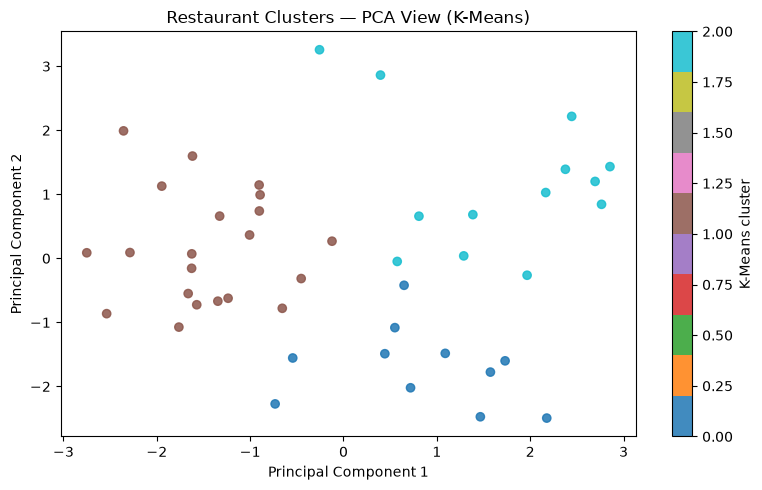

Variance explained by first two components: 0.744


In [12]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
restaurant_features["pca_1"] = X_pca[:, 0]
restaurant_features["pca_2"] = X_pca[:, 1]

plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    restaurant_features["pca_1"],
    restaurant_features["pca_2"],
    c=restaurant_features["kmeans_cluster"],
    cmap="tab10",
    alpha=0.85
)
plt.title("Restaurant Clusters — PCA View (K-Means)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="K-Means cluster")
plt.tight_layout()
plt.savefig(OUTPUTS / "restaurant_pca_kmeans.png", dpi=150)
plt.show()

print("Variance explained by first two components:",
      round(pca.explained_variance_ratio_.sum(), 3))

## 9. Cluster profiles and business names

The profile summarizes each cluster’s operational features. Business names are assigned using relative values from this synthetic dataset. Use the averages to validate whether each label is appropriate before presenting it as a business conclusion.

In [13]:
profile = restaurant_features.groupby("kmeans_cluster")[FEATURES].mean().round(2)
profile["restaurant_count"] = restaurant_features.groupby("kmeans_cluster")["restaurant_id"].count()
profile["share_percent"] = (
    profile["restaurant_count"] / len(restaurant_features) * 100
).round(1)

overall = restaurant_features[FEATURES].mean()

def restaurant_cluster_name(row, overall):
    if row["total_orders"] >= overall["total_orders"] and row["revenue"] >= overall["revenue"]:
        if row["average_rating"] >= overall["average_rating"]:
            return "High-Volume Top Performers"
        return "High-Volume Improvement Needed"
    if row["average_rating"] >= overall["average_rating"] and row["cancellation_rate"] < overall["cancellation_rate"]:
        return "Reliable Customer Favorites"
    if row["average_prep_time"] > overall["average_prep_time"] or row["average_delivery_time"] > overall["average_delivery_time"]:
        return "Operationally Slower Restaurants"
    return "Lower-Volume / Developing Restaurants"

profile["business_name"] = [
    restaurant_cluster_name(profile.loc[idx], overall) for idx in profile.index
]
display(profile)
profile.to_csv(OUTPUTS / "restaurant_cluster_profiles.csv")
restaurant_features.to_csv(PROCESSED / "restaurant_features_clustered.csv", index=False)

print("Saved: data/processed/restaurant_features_clustered.csv")
print("Saved cluster profile and plots under outputs/restaurant_segmentation/")

,total_orders,revenue,average_rating,average_prep_time,cancellation_rate,average_delivery_time,restaurant_count,share_percent,business_name
kmeans_cluster,,,,,,,,,
0,33.09,14805.19,3.53,28.18,0.08,58.06,11,24.4,Operationally Slower Restaurants
1,39.38,19056.50,3.86,15.14,0.08,45.47,21,46.7,Lower-Volume / Developing Restaurants
2,46.85,23812.02,3.46,27.92,0.06,59.08,13,28.9,High-Volume Improvement Needed


Saved: data/processed/restaurant_features_clustered.csv
Saved cluster profile and plots under outputs/restaurant_segmentation/


## 10. Export and verify deliverables

In [14]:
restaurant_features.to_csv(PROCESSED / "restaurant_features_clustered.csv", index=False)

print("Deliverables created:")
for path in [
    PROCESSED / "restaurant_features_clustered.csv",
    OUTPUTS / "restaurant_cluster_profiles.csv",
    OUTPUTS / "restaurant_elbow_plot.png",
    OUTPUTS / "restaurant_silhouette_scores.png",
    OUTPUTS / "restaurant_pca_kmeans.png",
    MODELS / "restaurant_standard_scaler.joblib",
    MODELS / "restaurant_kmeans.joblib",
    MODELS / "restaurant_dbscan.joblib",
]:
    print(("✓ " if path.exists() else "✗ "), path.relative_to(PROJECT_ROOT))

Deliverables created:
✓  data/processed/restaurant_features_clustered.csv
✓  outputs/restaurant_segmentation/restaurant_cluster_profiles.csv
✓  outputs/restaurant_segmentation/restaurant_elbow_plot.png
✓  outputs/restaurant_segmentation/restaurant_silhouette_scores.png
✓  outputs/restaurant_segmentation/restaurant_pca_kmeans.png
✓  models/restaurant_standard_scaler.joblib
✓  models/restaurant_kmeans.joblib
✓  models/restaurant_dbscan.joblib
